# 量子機械学習

Kifumi Numata, IBM Quantum (Nov 26, 2026)

Google Colab で行う場合は、次のセルの「#」を削除して実行します。

In [1]:
#%pip install "python-dateutil>=2.8.2,<3" "qiskit[visualization]" qiskit-ibm-runtime qiskit-aer scikit-learn

In [2]:
import qiskit
qiskit.__version__

'2.6.2'

### 目次:
1. データの符号化
2. 量子カーネル分類
3. 演習： 手書き文字の分類

# 1. データの符号化
## 1.1 基底エンコーディング

基底エンコーディング(basis encoding)は、古典的な $P$ ビットの文字列を $P$ 量子ビット系の計算基底状態にエンコードします。

$\vec{x} = (5,7,0)$ をエンコードしてみましょう。すべての特徴量が 4 ビットで格納されるとします (必要以上ですが、10 進数で 1 桁の任意の整数を表すには十分です)。

5 → 2 進数 0101

7 → 2 進数 0111

0 → 2 進数 0000

これらのビット列は 4 量子ビットずつの 3 つの組に割り当てられるため、全体の 12 量子ビットの基底状態は次のようになります。

$$∣0101 0111 0000⟩$$

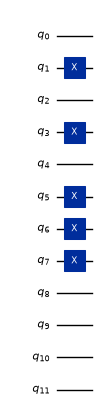

In [3]:
from qiskit import QuantumCircuit

# エンコードするデータ点
x = 5  # 2 進数: 0101
y = 7  # 2 進数: 0111
z = 0  # 2 進数: 0000

# それぞれを 4 ビットの 2 進数リストに変換
x_bits = [int(b) for b in format(x, "04b")]  # [0,1,0,1]
y_bits = [int(b) for b in format(y, "04b")]  # [0,1,1,1]
z_bits = [int(b) for b in format(z, "04b")]  # [0,0,0,0]

# すべてのビットを結合
all_bits = x_bits + y_bits + z_bits  # [0,1,0,1,0,1,1,1,0,0,0,0]

# 12 量子ビットの量子回路を初期化
qc = QuantumCircuit(12)

# ビットが 1 の位置に X ゲートを適用
for idx, bit in enumerate(all_bits):
    if bit == 1:
        qc.x(idx)

qc.draw("mpl", scale=0.5)

## 1.2 振幅エンコーディング

振幅エンコーディング(amplitude encoding)は、データを量子状態の振幅にエンコードします。
$\vec{x} = (4,8,5)$ を振幅エンコーディングでエンコードしてみましょう。まず、求めるベクトルを規格化するための定数 $\alpha$ を計算します。

$$\sum_{i=1}^N \left|x_i\right|^2 = 4^2+8^2+5^2 = 105 = \left|\alpha\right|^2 \rightarrow \alpha = \sqrt{105}$$

この定数を使い、データを計算基底の振幅の順に並べると、量子状態は次のようになります。

$$|\psi(\vec{x})\rangle = \frac{1}{\sqrt{105}}(4|00\rangle+8|01\rangle+5|10\rangle+0|11\rangle)$$

上の例では、ベクトルの要素数 $N=3$ は2のべき乗ではありません。$N$ が2のべき乗でない場合は、$2^n\geq N$ を満たす最小の $n$ を量子ビット数とし、残りの振幅はゼロで埋めます。今回は $n=2$ が最小なので、2量子ビットの状態として準備しました。

データセットをエンコードした状態を計算できれば、Qiskit の `initialize` 関数でその状態を準備できます。

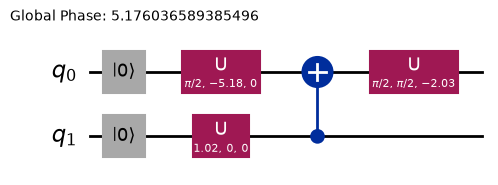

In [4]:
import math
desired_state = [
    1 / math.sqrt(105) * 4,
    1 / math.sqrt(105) * 8,
    1 / math.sqrt(105) * 5,
    1 / math.sqrt(105) * 0]

qc = QuantumCircuit(2)
qc.initialize(desired_state, [0,1])

qc.decompose(reps=5).draw(output = 'mpl')

この量子回路を測定してみましょう。データが確率振幅に反映されていることがわかります。

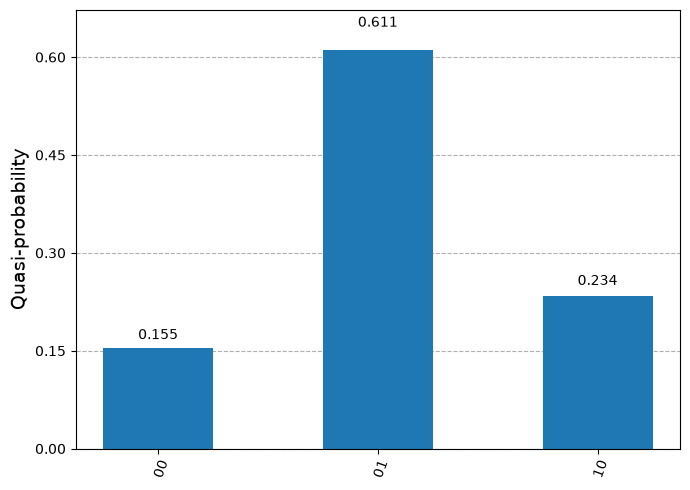

In [5]:
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.executor_sampler import Sampler

qc.measure_all()
backend = AerSimulator()
sampler = Sampler(backend)
job = sampler.run([qc])

counts = job.result()[0].data.meas.get_counts()

from qiskit.visualization import plot_distribution
plot_distribution(counts)   

## 1.3 角度エンコーディング

角度エンコーディング(angle encoding)は、データを $R_X$ ゲートや $R_Y$ ゲートなどの回転ゲートの角度にエンコードします。角度エンコーディングは、量子サポートベクターマシン(QSVM)や変分量子回路(VQC)など、量子特徴量マップを用いる量子機械学習アルゴリズムで重要です。

以下では、$\vec{x}= (0, \pi/4, \pi/2)$ を $R_Y$ ゲートでエンコードします。

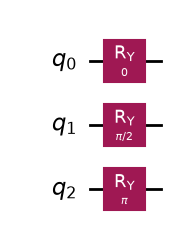

In [6]:
qc = QuantumCircuit(3)
qc.ry(0, 0)
qc.ry(2*math.pi/4, 1)
qc.ry(2*math.pi/2, 2)
qc.draw(output = 'mpl')

## 1.4 位相エンコーディング
位相エンコーディングは、上で説明した角度エンコーディングとよく似ています。量子ビットの位相角とは、$z$ 軸周りに +$x$ 軸から測った実数値の角度 $\phi$ のことです。

次の例では、まずアダマールゲートで回転させて単一の量子ビットの初期状態を準備し、次に位相ゲートで再び回転させてデータ特徴量 $\vec{x}^{(j)}_k=\frac{1}{2}\pi$ をエンコードします。

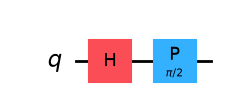

In [7]:
from math import pi
qc = QuantumCircuit(1)
qc.h(0)  # アダマールゲートが状態をブロッホ球の赤道まで回転させる
qc.p(pi / 2, 0)  # 位相ゲートが角度 pi/2 だけ回転させる
qc.draw("mpl", scale=1)

## 1.5 組み込みの特徴量マップによるエンコーディング

Qiskit の[回路ライブラリ](https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit_library)には、さまざまな特徴量マップが用意されています。

### Z 特徴量マップ

[`z_feature_map`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.z_feature_map)(ZFM)は、角度エンコーディングを自然に拡張したシンプルな特徴量マップです。以下では、2次元のデータに対して繰り返し回数3の ZFM の回路を作成します。

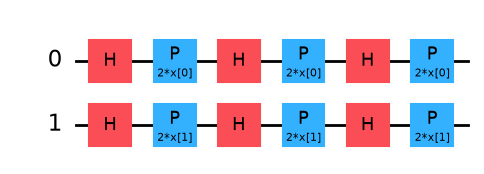

In [8]:
from qiskit.circuit.library import z_feature_map
from math import pi

zfeature_map = z_feature_map(feature_dimension=2, reps=3)
zfeature_map.draw("mpl")

`assign_parameters` を使ってパラメーターにデータを入力します。

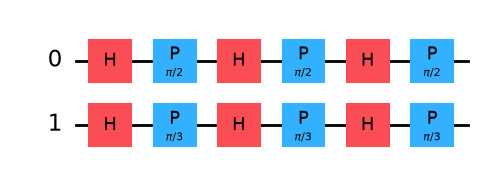

In [9]:
zfeature_map = zfeature_map.assign_parameters([(1/2)*pi/2, (1/2)*pi/3])
zfeature_map.draw("mpl")

### ZZ 特徴量マップ
[`zz_feature_map`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.zz_feature_map)(ZZFM)は、ZFM に2量子ビットのエンタングリングゲート、具体的には $ZZ$ 回転ゲート $R_{ZZ}(\theta)$ を加えて拡張したものです。ZFM とは異なり、ZZFM は一般に古典コンピューターでの計算コストが高いと予想されています。

以下は4次元のデータに対するもので、エンタングルメントは線形構造(`linear`)、繰り返しは ZZFM 回路1回分です。

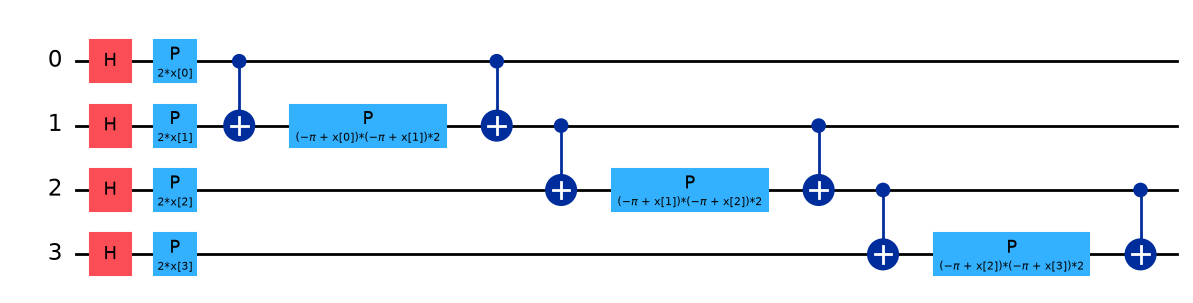

In [10]:
from qiskit.circuit.library import zz_feature_map
 
feature_dim = 4
zzfeature_map = zz_feature_map(
    feature_dimension=feature_dim, entanglement='linear', reps=1
)
zzfeature_map.draw("mpl", scale=1)

### パウリ特徴量マップ

[`pauli_feature_map`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.pauli_feature_map)(PFM)は、ZFM と ZZFM を任意のパウリゲートを使えるように一般化したものです。以下の PFM は3次元のデータに対するもので、エンタングルメントは `circular`(線形に加えて両端の量子ビットの組も結合する構造)、パウリ演算子は "Y" と "XX" です。

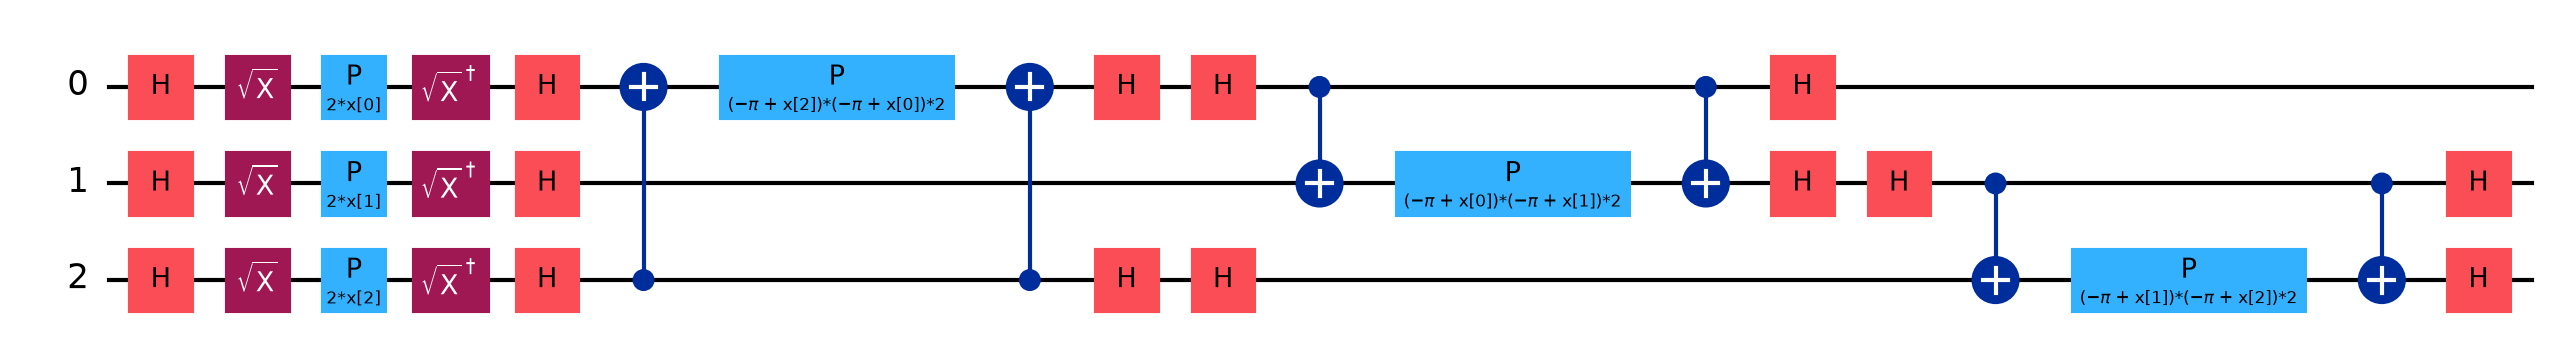

In [11]:
from qiskit.circuit.library import pauli_feature_map
 
feature_dim = 3
pfmap = pauli_feature_map(
    feature_dimension=feature_dim, entanglement='circular', reps=1, paulis=["Y", "XX"]
)
 
pfmap.draw("mpl", scale=1.5)

### efficient_su2

パラメーター化回路を特徴量マップとして使うこともできます。以下は、エンタングルメントを用いたエンコーディングの一般的で便利な例である [`efficient_su2`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.efficient_su2) 回路です。例えばこの回路では、わずか2量子ビットで8個の特徴量をエンコードできます。

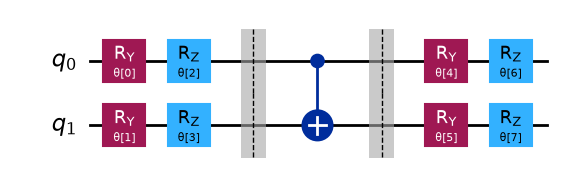

In [12]:
from qiskit.circuit.library import efficient_su2
 
circuit = efficient_su2(num_qubits=2, reps=1, insert_barriers=True)
circuit.draw(output="mpl")

# 2. 量子カーネル分類
## 2.1 カーネル行列の要素
### Step 1: 古典の入力を量子の問題にマッピングする
まず、数個の特徴量（例えば4個）を持つデータセットを考えてみましょう。カーネル行列の要素を計算するために少なくとも2つのデータポイントが必要なので、まずそこから始め、必要なパッケージをいくつかインポートします：

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# ラベルを含む学習用の2つのデータポイント
small_data = [[-0.194,0.114,-0.006,0.301,1],[-0.1,0.002,0.244,0.127,-1]]

# 内積計算のためにラベルを除去したデータ点
train_data = [small_data[0][:-1],small_data[1][:-1]]

#### 符号化

このデータを量子特徴量マップを使って量子状態に符号化(エンコード)します。`zz_feature_map`を試してみます。

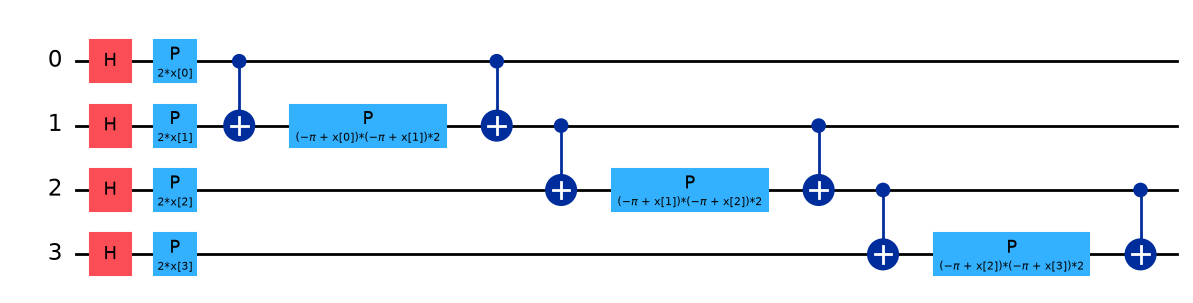

In [14]:
from qiskit.circuit.library import zz_feature_map

zz_fm = zz_feature_map(feature_dimension=np.shape(train_data)[1], entanglement='linear', reps=1)

zz_fm.draw("mpl", fold=-1)

上記で用意した `train_data` を、`zz_feature_map`を使って量子状態にマッピングします。

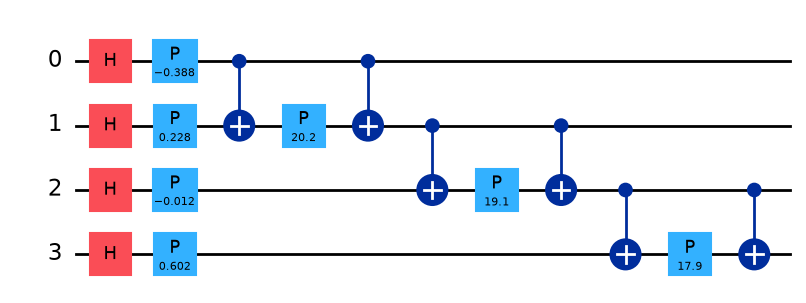

In [15]:
unitary1 = zz_fm.assign_parameters(train_data[0])
unitary2 = zz_fm.assign_parameters(train_data[1])

unitary1.draw("mpl", fold=-1)

次に、 `unitary_overlap` を使用して量子カーネル行列の1つの要素を計算する量子回路を作成します。また、回路のDepthを確認します。

circuit depth =  23


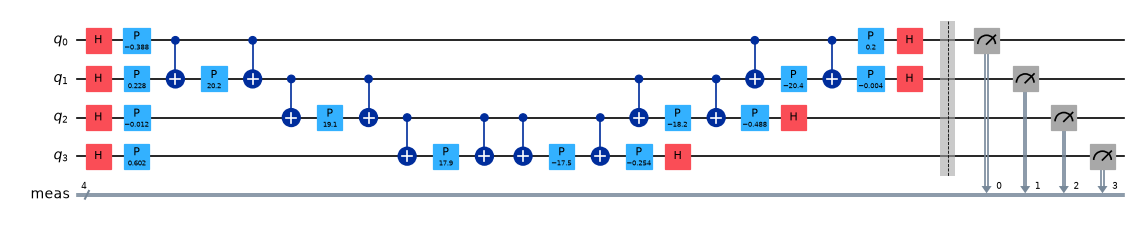

In [16]:
from qiskit.circuit.library import unitary_overlap
overlap_circ = unitary_overlap(unitary1, unitary2)
overlap_circ.measure_all()

print("circuit depth = ", overlap_circ.decompose().depth())
overlap_circ.draw("mpl", scale=0.6, fold=-1)

回路が左右対称であることがわかります。左半分に学習データ `train_data[0]` 、右半分に学習データ `train_data[1]` がエンコードされています。

### Step 2: 実行のための問題の最適化

Aer Simulatorをバックエンドとして使い、上記の回路を最適化します。今回は、実機のバックエンドを使用しませんが、sampler が ZZFeatureMap を認識できないため、回路をトランスパイルする必要があります。

In [17]:
# シミュレーターを使います
from qiskit_aer import AerSimulator
backend = AerSimulator()

# 回路を最適化します
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
overlap_ibm = pm.run(overlap_circ)

### Step 3: Qiskit Runtime Primitivesを使って実行する

Qiskit Runtime Primitivesを使って回路を実行します。

In [18]:
# シミュレーターを使います
from qiskit_ibm_runtime.executor_sampler import Sampler
num_shots = 10000
sampler = Sampler(mode=backend)
results = sampler.run([overlap_ibm], shots=num_shots).result()

# .get_counts() は、|001101...01> のようなビットの結果でラベル付けされた状態に対応するカウントを返します。
counts_bit = results[0].data.meas.get_counts()
# .get_int_counts() は同じカウントを返しますが、ラベルは上記のビット列に相当する整数になります。
counts = results[0].data.meas.get_int_counts()

print(counts_bit)

{'0000': 6959, '0110': 1452, '0100': 566, '1100': 283, '1000': 236, '0010': 160, '1010': 99, '1110': 97, '0001': 76, '0011': 48, '1111': 4, '1001': 3, '1101': 6, '0111': 7, '0101': 3, '1011': 1}


### Step 4: 後処理を行い、古典の形式で結果を返す

ここで最も有用となる測定は、ゼロの状態 $|0000\rangle$ を測定する確率です。

In [19]:
counts.get(0, 0.0)/num_shots #キー0の値(なければ0.0を返す)

0.6959

カーネル行列の要素の1つをこれで計算できました。次に、カーネル行列のすべての要素を計算します。

## 2.2 完全なカーネル行列

このセクションでは、上記のプロセスを完全なデータセットの2値分類に拡張します。ここでの特徴量マップは、Qiskitの組み込みfeature mapを使わずに、自作します。完全なカーネル行列を作ったあと、古典の機械学習を実装し、学習精度のスコアを求めます。

### Step 1: 古典の入力を量子の問題にマッピングする
ここで、分類のために既存のデータセットをインポートします。このデータセットは128行（データポイント）と各ポイントにおける14個の特徴量からなります。また、各ポイントにはバイナリーのカテゴリー ($\pm 1$) を示す15番目の要素があります。データセットは以下でインポートされます。また、[ここ](https://github.com/qiskit-community/prototype-quantum-kernel-training/blob/main/data/dataset_graph7.csv)からデータセットにアクセスしてその構造を見ることもできます。

128のデータポイントのうち、最初の60データポイントを学習に使い、次の20ポイントをテストに使います。

In [20]:
import os
import urllib.request

url = "https://raw.githubusercontent.com/qiskit-community/prototype-quantum-kernel-training/main/data/dataset_graph7.csv"
if not os.path.exists("dataset_graph7.csv"):
    urllib.request.urlretrieve(url, "dataset_graph7.csv")

In [21]:
import pandas as pd
df = pd.read_csv("dataset_graph7.csv", sep=",", header=None)

# 学習データの準備
train_size = 60
X_train=df.values[0:train_size,:-1]
train_labels = df.values[0:train_size,-1]

# テストデータの準備
test_size = 20
X_test=df.values[train_size:train_size+test_size,:-1]
test_labels=df.values[train_size:train_size+test_size,-1]

出力を格納するために、空のカーネル行列と、適切な次元の空のテスト用カーネル行列を作ります。

In [22]:
# 空のカーネル行列
num_samples = np.shape(X_train)[0]
kernel_matrix = np.full((num_samples, num_samples), np.nan) # 60x60の学習用カーネル行列
test_matrix = np.full((test_size, num_samples), np.nan) # 20x60のテスト用カーネル行列

次に、古典データを量子回路に符号化するための特徴量マップを自作します。

In [23]:
from qiskit.circuit import Parameter, ParameterVector, QuantumCircuit

# overlapを計算するための特徴量の準備
num_features = np.shape(X_train)[1] #14
num_qubits = int(num_features / 2) #7

# カスタムのfeature mapでは、以下の行をエンタングルメントさせます
entangler_map = [[0, 2], [3, 4], [2, 5], [1, 4], [2, 3], [4, 6]]

fm = QuantumCircuit(num_qubits)
training_param = Parameter("θ")
feature_params = ParameterVector("x", num_qubits * 2)
fm.ry(training_param, fm.qubits) # pi/2回転なのでHゲートと等価
for cz in entangler_map:
    fm.cz(cz[0], cz[1])
for i in range(num_qubits):
    fm.rz(-2 * feature_params[2 * i + 1], i)
    fm.rx(-2 * feature_params[2 * i], i)

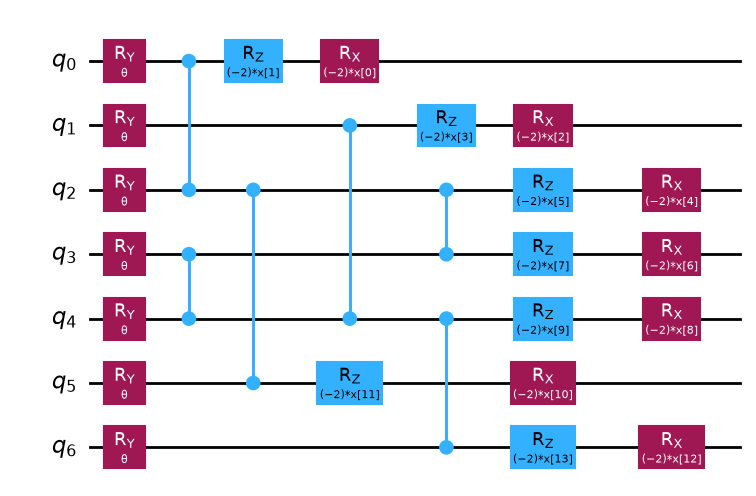

In [24]:
fm.draw("mpl") # 各qubitに2つのデータをエンコードするため7qubit回路

### Step 2 & 3: 問題を最適化し、primitiveを使って実行する

Overlap回路を作ります。カーネル行列は対角に対して対称なので、同じ計算は繰り返さないようにすることで、計算回数は二分の一に減らせます。また、ノイズがない場合は対角要素が1となるため、今回は対角要素を計算せず、1を代入します。(60×60×1/2-60)要素と(20×60)要素の合計2920要素を計算するので、以下のセルは実行にすこし時間がかかります。

In [25]:
num_shots = 1000

backend = AerSimulator()
sampler = Sampler(mode=backend)

for x1 in range(0,train_size):
    for x2 in range(x1+1,train_size):
        unitary1 = fm.assign_parameters(list(X_train[x1]) + [np.pi / 2]) #パラメーターは名前のアルファベット順に並ぶ
        unitary2 = fm.assign_parameters(list(X_train[x2]) + [np.pi / 2]) #今回は x の次に θ

        # Overlap回路の作成
        overlap_circ = unitary_overlap(unitary1, unitary2)
        overlap_circ.measure_all()
    
        # Qiskit sampler primitiveの実行
        counts = (
            sampler.run([overlap_circ], shots=num_shots).result()[0].data.meas.get_int_counts()
        )

        # |0>状態の確率をカーネル行列の要素に入れ、転置された要素にも同じ確率を入れます。
        kernel_matrix[x1, x2] = counts.get(0, 0.0)/num_shots
        kernel_matrix[x2, x1] = counts.get(0, 0.0)/num_shots
    # 確率の内積なので、対角線上の要素を1で埋めます
    kernel_matrix[x1,x1] =1    

print("training done")

# 上記と同様のプロセスをテストデータを使って行う
for x1 in range(0,test_size):
    for x2 in range(0,train_size):
        unitary1 = fm.assign_parameters(list(X_test[x1]) + [np.pi / 2])
        unitary2 = fm.assign_parameters(list(X_train[x2]) + [np.pi / 2])

        # Overlap回路の作成
        overlap_circ = unitary_overlap(unitary1, unitary2)
        overlap_circ.measure_all()
    
        counts = (
            sampler.run([overlap_circ], shots=num_shots).result()[0].data.meas.get_int_counts()
        )

        test_matrix[x1, x2] = counts.get(0, 0.0)/num_shots

print("test matrix done")

training done
test matrix done


2つのカーネル行列を見てみましょう。

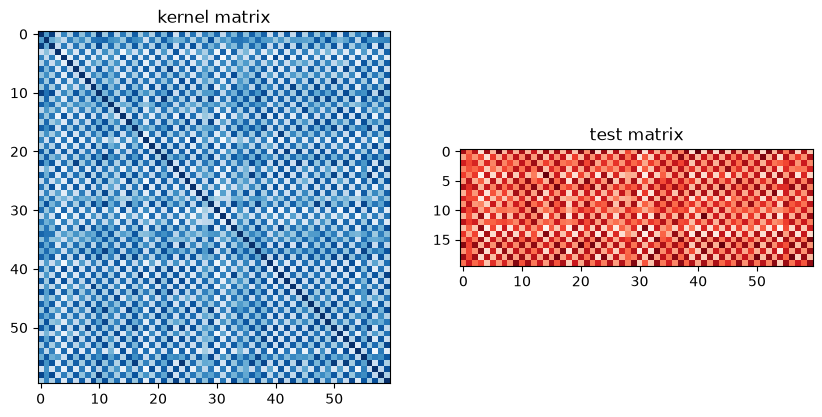

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(np.asmatrix(kernel_matrix),
              interpolation='nearest', origin='upper', cmap='Blues')
axs[0].set_title("kernel matrix")
axs[1].imshow(np.asmatrix(test_matrix),
              interpolation='nearest', origin='upper', cmap='Reds')
axs[1].set_title("test matrix")
plt.show()

### Step 4: 後処理を行い、古典の形式で結果を返す

量子カーネル法からカーネル行列と同様の形式の test_matrix が得られたので、古典の機械学習アルゴリズムを適用してテストデータの予測を行い、その精度をチェックすることができます。まず、Scikit-Learnの`sklearn.svc`、サポートベクトル分類器（SVC）をインポートします。SVC に事前に計算したカーネルを使わせたい場合は、`kernel = precomputed` を使って指定します。

In [27]:
# 古典の機械学習パッケージからサポートベクトル分類器をインポート
from sklearn.svm import SVC

# 事前に計算されたカーネル行列を使用することを指定
qml_svc = SVC(kernel="precomputed")

`SVC.fit` を使って、カーネル行列と学習用ラベルを入力し、fitを得ることができます。`SVC.predict` は test_matrix を使ってテストデータのラベルを予測します。`SVC.score` はテストデータをスコアリングして精度を返します。

In [28]:
# 事前に計算された行列と学習データのラベルを入力。古典アルゴリズムがfitを行います。
qml_svc.fit(kernel_matrix, train_labels)

# 学習データとテストデータのカーネル行列を用いてテストデータのラベルを予測します。
label_predict = qml_svc.predict(test_matrix)
print(label_predict, test_labels, sep="\n")

# テストデータの行列とテストラベルを入力として、.scoreを使ってデータをテストします。
qml_score_precomputed_kernel = qml_svc.score(test_matrix, test_labels)
print(f"Precomputed kernel classification test score: {qml_score_precomputed_kernel}")

[ 1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.
  1. -1.]
[ 1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.
  1. -1.]
Precomputed kernel classification test score: 1.0


学習したモデルの精度は100%でした。これは素晴らしいことで、QKE(Quantum Kernel Estimation)が機能することを示しています。しかし、これは量子の優位性ではありません。古典カーネルでも、おそらくこの分類問題を100%の精度で解くことができるでしょう。現在のユーティリティ時代に量子カーネルが最も役立つのはどこなのか、さまざまなデータタイプやデータ関係を特徴づけるためにやるべきことはたくさんあります。量子特徴量マップを変更してその有効性を研究してみてください。

特徴量マップを自作する例として、以下のようなアイディアが報告されています。
- 相関のある特徴量どうしを、エンタングルメントでつなぐ([Covariant quantum kernels for data with group structure](https://arxiv.org/abs/2105.03406))
- 特徴量のスケール(回転角に掛ける係数)を調整する([Importance of kernel bandwidth in quantum machine learning](https://link.aps.org/doi/10.1103/PhysRevA.106.042407)、[Bandwidth enables generalization in quantum kernel models](https://arxiv.org/abs/2206.06686))
- 深さ・エンタングルメントを増やしすぎない([Exponential concentration in quantum kernel methods](https://www.nature.com/articles/s41467-024-49287-w))
- カーネル・アラインメントで理想的なカーネルと比較して、特徴量マップの評価を簡単に行う([Training quantum embedding kernels on near-term quantum computers](https://link.aps.org/doi/10.1103/PhysRevA.106.042431))

また、符号化した回路からパウリ行列の期待値を射影測定で求め、そのベクトル同士の距離をガウスカーネルで求める射影量子カーネル(PQK)という手法も知られており、[こちらのチュートリアル](https://quantum.cloud.ibm.com/docs/en/tutorials/projected-quantum-kernels)では、実際の生物データセットに対してPQKによる分類を実装しています。

## 3. 演習: 手書き文字の分類

手書き数字画像データセット（MNISTデータセット）から`0`と`1`の部分集合を扱い、QKEを実行してみます。

In [29]:
# Scikit-learnのインポート
from sklearn import datasets
from sklearn.model_selection import train_test_split 
from sklearn.svm import SVC 
from sklearn.decomposition import PCA # Principal component analysis(主成分分析)
from sklearn.preprocessing import StandardScaler, MinMaxScaler 

### Step 1: 古典の入力を量子の問題にマッピングする

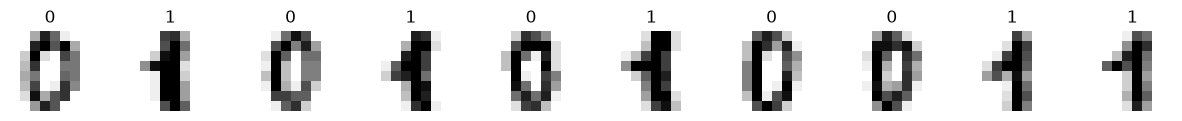

In [30]:
# 数値データセットから2つのクラス（0と1）のデータをロードする
digits = datasets.load_digits(n_class=2)   

# ロードした最初の10個の画像をプロット
fig, axes = plt.subplots(1, 10, figsize=(15, 15), subplot_kw={'xticks':[], 'yticks':[]}, gridspec_kw=dict(hspace=0.5, wspace=0.5))
for i, ax in enumerate(axes.flat):
    ax.set_axis_off()
    ax.imshow(digits.images[i], cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(digits.target[i])

以下のデータ配列に`0` が見えるかもしれません。0は白、16が黒に対応しています。

In [31]:
print(digits.images[0])

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


このデータセットには、合計360個のデータが含まれています。各データポイントは、8×8の数字の画像で、配列になっていて、各要素は0（白）から16（黒）までの整数です。古典的な分類アルゴリズムの際と同様に、データセットを学習用（25個）とテスト用（10個）のサンプルに分割し、正規化する必要があります。このデータセットを量子分類アルゴリズムに用いるために、範囲を-1から1の間にスケーリングし、次元を使用する量子ビット数（今回は4）に縮小します。

In [32]:
# データセットの分割
sample_train, sample_test, labels_train, labels_test = train_test_split(
     digits.data, digits.target, test_size=0.4, random_state=22)

# 次元削除
n_dim = 4
pca = PCA(n_components=n_dim).fit(sample_train)
sample_train = pca.transform(sample_train)
sample_test = pca.transform(sample_test)

# 正規化
std_scale = StandardScaler().fit(sample_train)
sample_train = std_scale.transform(sample_train)
sample_test = std_scale.transform(sample_test)

# スケーリング
samples = np.append(sample_train, sample_test, axis=0)
minmax_scale = MinMaxScaler((-1, 1)).fit(samples)
sample_train = minmax_scale.transform(sample_train)
sample_test = minmax_scale.transform(sample_test)

# 学習用25個とテスト用10個を選択
train_size = 25
X_train = sample_train[:train_size]
train_labels = labels_train[:train_size]

test_size = 10
X_test = sample_test[:test_size]
test_labels = labels_test[:test_size]

In [33]:
# 一つ目のデータを表示
print(X_test[0])

[0.41456664 0.7486731  0.74168091 0.32496914]


### 演習 1: 

`zz_feature_map`を使って特徴量マップの回路を作ってください。(`zz_feature_map`はこのNotebookの最初で使っています。)

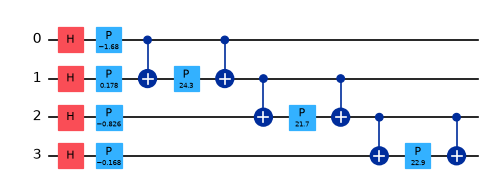

In [34]:
from qiskit.circuit.library import zz_feature_map
fm = ??? # 特徴量マップの回路を作ってください。

unitary1 = fm.assign_parameters(X_train[0]) 
unitary2 = fm.assign_parameters(X_train[1]) 

unitary1.draw("mpl", scale=0.6, fold=-1)

circuit depth =  23


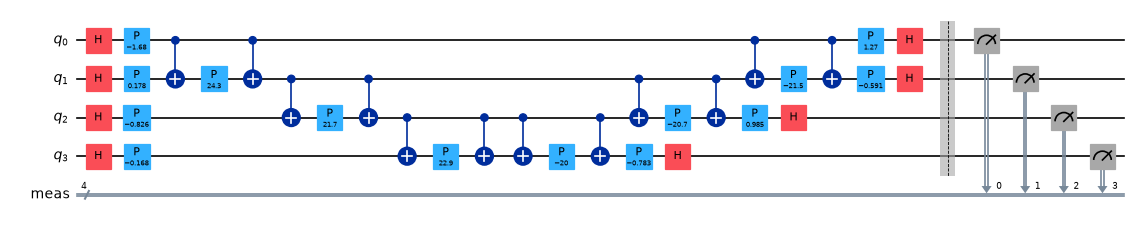

In [35]:
overlap_circ = unitary_overlap(unitary1, unitary2)
overlap_circ.measure_all()

print("circuit depth = ", overlap_circ.decompose().depth())
overlap_circ.draw("mpl", scale=0.6, fold=-1)

In [36]:
# 空のカーネル行列の作成
num_samples = np.shape(X_train)[0]
kernel_matrix = np.full((num_samples, num_samples), np.nan) # Matrix of 40x40
test_matrix = np.full((test_size, num_samples), np.nan) # Matrix of 10x40

### Step 2 & 3: 問題を最適化し、primitiveを使って実行する

### 演習 2: 

unitary_overlap を計算するために必要な、unitary1とunitary2の回路のパラメーターにデータをアサインしてください。上の演習で作った、featuremapを使います。

In [37]:
num_shots = 1000

backend = AerSimulator()
sampler = Sampler(mode=backend)


for x1 in range(0,train_size):
    for x2 in range(x1+1,train_size):
        unitary1 = ?? # fmのパラメーターにデータをアサインしてください
        unitary2 = ?? # fmのパラメーターにデータをアサインしてください
        
        # Overlap回路の作成
        overlap_circ = unitary_overlap(unitary1, unitary2)
        overlap_circ.measure_all()

        # 回路の最適化
        pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
        overlap_ibm = pm.run(overlap_circ)
    
        # Qiskit sampler primitiveの実行
        counts = (
            sampler.run([overlap_ibm], shots=num_shots).result()[0].data.meas.get_int_counts()
        )

         # |0>状態の確率をカーネル行列の要素に入れ、転置された要素にも同じ確率を入れます。
        kernel_matrix[x1, x2] = counts.get(0, 0.0)/num_shots
        kernel_matrix[x2, x1] = counts.get(0, 0.0)/num_shots
    # 確率の内積なので、対角線上の要素を1で埋めます
    kernel_matrix[x1,x1] =1    

print("training done")

# 上記と同様のプロセスをテストデータを使って行う
for x1 in range(0,test_size):
    for x2 in range(0,train_size):
        unitary1 = ?? # fmのパラメーターにデータをアサインしてください
        unitary2 = ?? # fmのパラメーターにデータをアサインしてください        
        
        # Overlap回路の作成
        overlap_circ = unitary_overlap(unitary1, unitary2)
        overlap_circ.measure_all()

        # 回路の最適化
        pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
        overlap_ibm = pm.run(overlap_circ)
    
        counts = (
            sampler.run([overlap_ibm], shots=num_shots).result()[0].data.meas.get_int_counts()
        )

        test_matrix[x1, x2] = counts.get(0, 0.0)/num_shots

print("test matrix done")

training done
test matrix done


kernel_matrixとtest_matrixを見てみましょう。

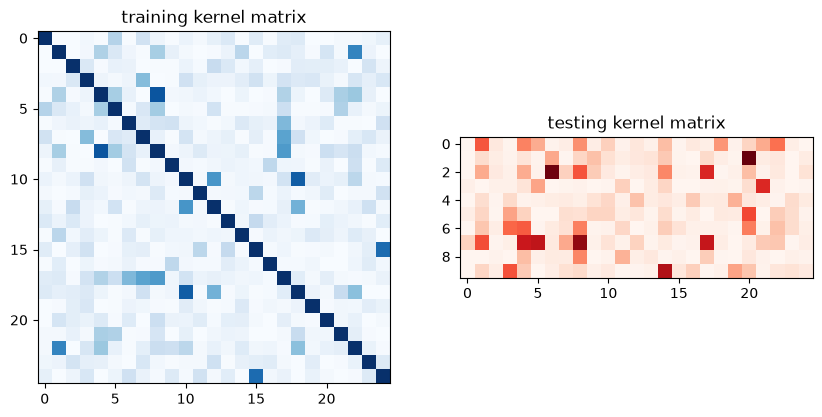

In [38]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(np.asmatrix(kernel_matrix),
              interpolation='nearest', origin='upper', cmap='Blues')
axs[0].set_title("training kernel matrix")
axs[1].imshow(np.asmatrix(test_matrix),
              interpolation='nearest', origin='upper', cmap='Reds')
axs[1].set_title("testing kernel matrix")
plt.show()

### Step 4: 後処理を行い、古典の形式で結果を返す

古典機械学習のアルゴリズムを適用して、テストデータの予測を行い、その精度をチェックします。

In [39]:
# 事前に計算されたカーネル行列を使用することを指定
qml_svc = SVC(kernel="precomputed")

# 事前に計算された行列と学習データのラベルを入力。古典アルゴリズムがfitを行います。
qml_svc.fit(kernel_matrix, train_labels)

# 学習データとテストデータのカーネル行列を用いてテストデータのラベルを予測します。
label_predict = qml_svc.predict(test_matrix)
print(label_predict, test_labels, sep="\n")

# テストデータの行列とテストラベルを入力として、.scoreを使ってデータをテストします。
qml_score_precomputed_kernel = qml_svc.score(test_matrix, test_labels)
print(f"Precomputed kernel classification test score: {qml_score_precomputed_kernel}")

[0 1 0 1 1 1 0 0 1 0]
[1 1 0 1 1 1 0 0 1 0]
Precomputed kernel classification test score: 0.9


スコアはどうでしたか？もし時間があれば、他のfeaturemapも試してみてください。

© IBM Corp., 2026